# Demo: The Whole Loop on One Series

**Master's Thesis Project:** Seasonality-Aware Drift Detection System
One hourly series with a visible change goes through every step of the system, one call at a time:

1. the series and the deployed forecasting model: where the problem is;
2. the drift detector of stream A: when it raises an alarm;
3. the advisor of stream B: what the LLM gets and what it proposes;
4. the backtest check: whether the proposal is applied;
5. the result: the forecast error with the system and without it.

At the end the same series plays in the monitoring service with Grafana. The functions called here are the ones the service runs.

In [1]:
import sys
import os

import pandas as pd

# Adds the parent directory (project root) to the Python path
sys.path.append(os.path.abspath(os.path.join('..')))

from src.api.uploads import calibrate_on_history
from src.recommendations import demo
from src.recommendations.alarms import alarms_of
from src.recommendations.backtester import StrategyRun, check_action, mase
from src.recommendations.catalog import ACTIONS
from src.recommendations.forecast import DAY
from src.recommendations.llm_client import LLMAdvisor, diagnostics, render_prompt
from src.recommendations.monitor import STRATEGY_BY_NAME, Monitor

## 1. The Series

The input is a CSV with two columns, `timestamp` and `value`, one row per hour. `load_series` checks and prepares it with the code behind `POST /series/csv` of the service, so any series in this format can take its place. Two dates are given with it: when the forecasting model goes to work, and (only for the report of the error) when the change starts.

4032 hourly values, 02.09.2013 to 16.02.2014
the model goes to work on 11.11.2013, the change starts on 02.12.2013


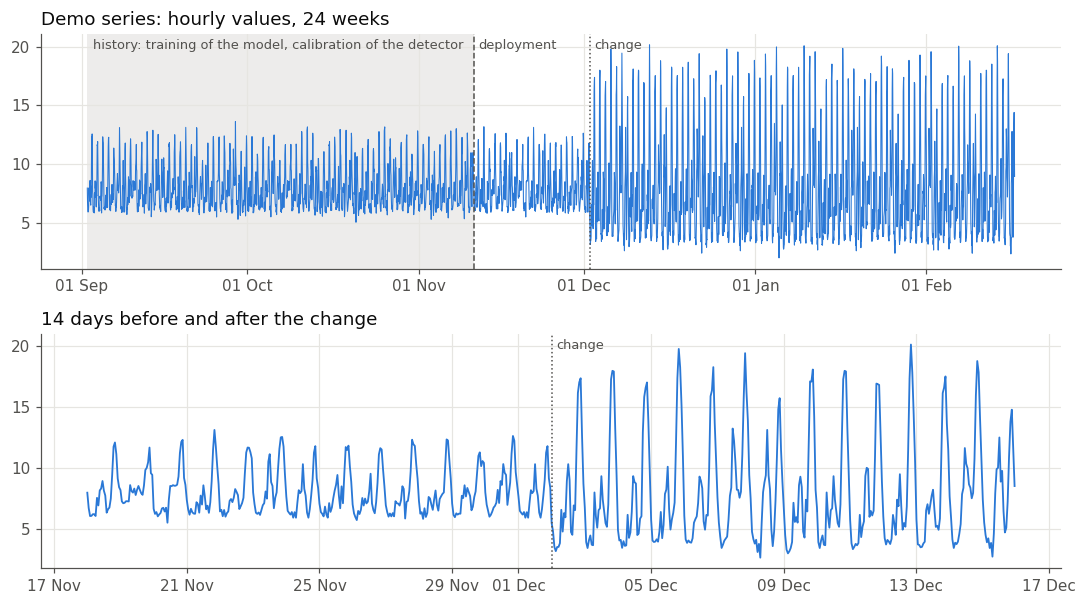

In [2]:
s = demo.load_series(demo.DEMO_CSV, deploy_at="2013-11-11", change_at="2013-12-02")
y, F, t_deploy, t_change = s["y"], s["F"], s["t_deploy"], s["t_change"]
t = demo.stamps(s)

print(f"{len(y)} hourly values, {t[0]:%d.%m.%Y} to {t[-1]:%d.%m.%Y}")
print(f"the model goes to work on {t[t_deploy]:%d.%m.%Y}, the change starts on {t[t_change]:%d.%m.%Y}")
demo.plot_series(s)

From 2 December the weekly swing of the series is 2.5 times larger, while its level stays the same. The first ten weeks are the history: the model is trained on it and the detector is calibrated on it.

## 2. The Deployed Model: Where the Problem Is

A LightGBM model is trained on the history and from 11 November forecasts the next 24 hours every day at 00:00. `StrategyRun` with the strategy `nothing` is this model left without any change.

Forecast error (MASE) before the change: 0.90, after the change: 3.44


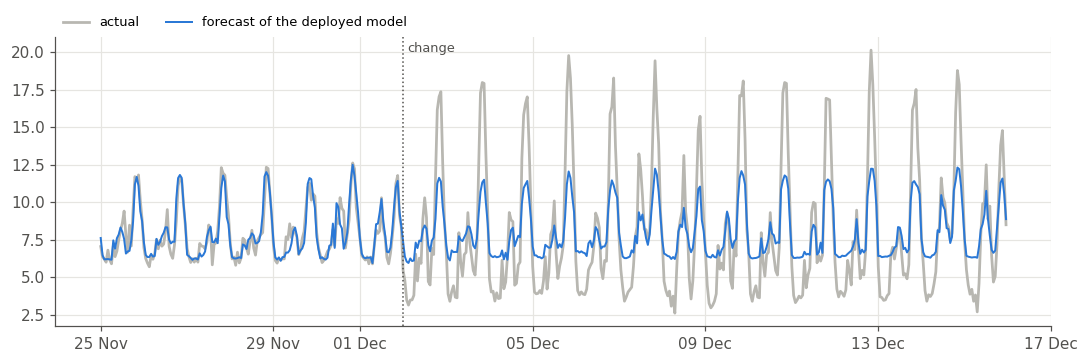

In [3]:
deployed = StrategyRun(y, F, t_deploy, STRATEGY_BY_NAME["nothing"], s["base_features"])  # trains the model on the history
for origin in deployed.origins:   # every day at 00:00
    deployed.step(origin)         # the forecast of the next 24 hours

before = mase(y, deployed.pred, t_deploy, t_change, deployed.scale)
after = mase(y, deployed.pred, t_change, deployed.end, deployed.scale)
print(f"Forecast error (MASE) before the change: {before:.2f}, after the change: {after:.2f}")
demo.plot_forecast(s, deployed.pred)

The error is 0.90 before the change and 3.44 after it (MASE: 1.0 is the error of repeating the value of a week ago). The model keeps forecasting the old swing, and nothing tells its owner. This is the problem the system solves.

## 3. The Drift Detector (Stream A)

The detector removes the seasonal pattern with an STL decomposition and watches the residuals with conformal thresholds. Its sensitivity is set on the history of the series itself, to one false alarm per 14 days.

**Input:** the values as they arrive. **Output:** the times of the alarms.

Sensitivity multiplier: 2.75


,time,hours after the change
0,2013-12-02 23:00:00,23
1,2013-12-23 23:00:00,527
2,2013-12-27 23:00:00,623


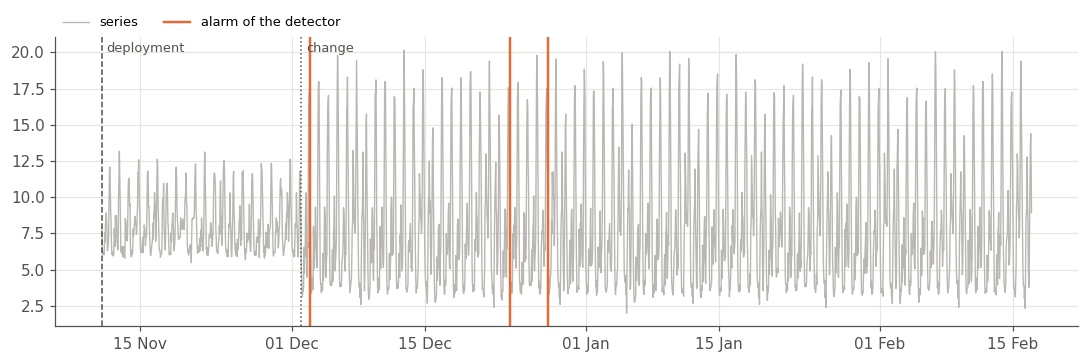

In [4]:
setting = pd.DataFrame(calibrate_on_history(s)).set_index("method")
multiplier = float(setting.loc["residual_conformal", "value"])   # sensitivity calibrated on the history

alarms = alarms_of("residual_conformal", s, multiplier)
alarms["time"] = t[alarms["index"]]
alarms["hours after the change"] = alarms["index"] - t_change

print("Sensitivity multiplier:", multiplier)
display(alarms[["time", "hours after the change"]])
demo.plot_alarms(s, alarms)

There is no alarm in the three weeks before the change, and the first alarm comes 23 hours after it. Every alarm goes to the next step: at the next 00:00 the model is reviewed.

## 4. The Advisor (Stream B)

At a review the system describes the situation in a few numbers computed from the data so far (`diagnostics`), puts them into a prompt (`render_prompt`) and asks the advisor for one action from a fixed catalog. The advisor here is an LLM (Claude Sonnet 5.5 through OpenRouter). Its answers on this series are stored in the repository, so the notebook runs without an API key.

**Input:** the diagnostics at the review. **Output:** one action and the reason.

In [5]:
first_alarm = int(alarms["index"].iloc[0])
T = (first_alarm // DAY + 1) * DAY   # the review: the first 00:00 after the alarm

context = diagnostics(y, deployed.pred, T, t_deploy, deployed.scale, last_change=t_deploy,
                      alarm=dict(method="residual_conformal", hours_ago=T - first_alarm))
system_prompt, user_prompt = render_prompt(context)
print(system_prompt)
print()
print(user_prompt)

You maintain an hourly forecasting model in production. Every day at 00:00 it forecasts the next
24 hours (gradient boosting on lagged values and calendar features). At a review point you get diagnostics
computed from the data up to now and choose exactly one action from the catalog. Every retraining has a
cost, so choose "keep" when the evidence for a change is weak.

Catalog:
- keep: do nothing (no retraining)
- retrain_full: retrain on all history (retrains the model)
- retrain_8w: retrain on the last 8 weeks (retrains the model)
- retrain_2w: shorten the training window to 2 weeks (retrains the model)
- reweight_1w: reweight recent data (weight half-life 1 week) (retrains the model)
- add_profile: add a seasonal feature: 4-week hour-of-week profile (retrains the model)
- recalibrate_level: recalibrate the forecast level on the last week (no retraining)

Answer with the action name and a short reason.

Diagnostics (errors are MASE: 1.0 = error of the weekly seasonal naive forecast o

In [6]:
advisor = LLMAdvisor(demo.LLM_MODEL, cache_dir=demo.LLM_ANSWERS)
answer = advisor.recommend(context)

print(f"Review of {t[T]:%d.%m.%Y}")
print("Proposed action:", answer.action)
print("Reason:", answer.reason)

Review of 03.12.2013
Proposed action: retrain_8w
Reason: Error rose from 0.94 at deployment to 0.79, 1.1, 1.26 over the last weeks, and the drift detector alarmed an hour ago. The level fell by 0.18 (bias -0.11) and daily amplitude is 1.2x, with noise at 1.46x. Because the level shift is not the only change, recalibrating alone would not suffice. Retraining on the last 8 weeks drops the stale older regime while keeping enough data (13.1 weeks available)


The LLM reads the diagnostics and proposes to retrain the model on the last 8 weeks. This is a proposal: nothing is changed yet.

## 5. The Backtest Check

`check_action` replays the proposed action on the last two weeks and compares it with the forecasts that were actually made. The action is applied only if the lower bound of the 95% interval of the gain is above zero.

**Input:** the proposed action. **Output:** the gain with its interval and the decision.

In [7]:
check = check_action(ACTIONS[answer.action], deployed.model, y, F, deployed.pred, T, deployed.scale, deployed.act)

decision = "accepted, the model is changed" if check["accepted"] else "not accepted, the model stays"
print(f"Gain of {answer.action}: {check['gain']:+.3f}, 95% interval [{check['lo']:+.3f}, {check['hi']:+.3f}]: {decision}")

Gain of retrain_8w: +0.002, 95% interval [-0.019, +0.028]: not accepted, the model stays


One day after the change the last two weeks hold almost only old data, so the check finds no gain and the model stays. The check protects the model from changes without evidence. The proposal is not forgotten: the model is reviewed again in a week.

## 6. Follow-up Reviews

A proposal that the check did not confirm is reviewed again every 7 days, for at most three weeks. Each follow-up makes the same three calls: diagnostics, advisor, check.

In [8]:
for T_next in (T + 7 * DAY, T + 14 * DAY):
    context = diagnostics(y, deployed.pred, T_next, t_deploy, deployed.scale, last_change=t_deploy,
                          alarm=dict(method="residual_conformal", hours_ago=T_next - first_alarm))
    answer = advisor.recommend(context)
    check = check_action(ACTIONS[answer.action], deployed.model, y, F, deployed.pred, T_next, deployed.scale, deployed.act)

    decision = "accepted, the model is changed" if check["accepted"] else "not accepted, the model stays"
    print(f"Review of {t[T_next]:%d.%m.%Y}: the LLM proposes {answer.action}")
    print(f"  gain {check['gain']:+.3f}, 95% interval [{check['lo']:+.3f}, {check['hi']:+.3f}]: {decision}")
print("Reason of the last proposal:", answer.reason)

Review of 10.12.2013: the LLM proposes retrain_2w
  gain +0.402, 95% interval [-0.005, +0.814]: not accepted, the model stays


Review of 17.12.2013: the LLM proposes retrain_8w
  gain +1.131, 95% interval [+0.324, +1.906]: accepted, the model is changed
Reason of the last proposal: Error rose from 0.94 at deployment to 3.99 and 3.56 in the last weeks, and a drift alarm fired about 2 weeks ago, so the change is persistent. The daily amplitude is 1.76x larger and noise is 1.36x higher, while bias (-0.32) and the level shift (-0.2) are small. The problem is a structural change, not a level offset, so recalibrating the level would not fix it. Retraining on the last 8 weeks drops


On 10 December the gain is already visible, but its interval still reaches below zero, so the model stays. On 17 December the check has a full week of forecasts from a candidate trained on the new data: the gain is confirmed and the model is retrained on the last 8 weeks, 15 days after the change.

## 7. The Whole Loop and the Result

`Monitor` is the engine of the service: it reads the series hour by hour and makes the same calls on its own. The strategy `alarm_llm_gate_follow` means: review on an alarm, LLM advisor, backtest check, follow-up reviews.

In [9]:
monitor = Monitor(s, "alarm_llm_gate_follow", detector="residual_conformal", detector_value=multiplier, advisors={"llm": advisor})
events = monitor.advance(len(y))   # reads all values after the deployment

print("Requests sent to the LLM in this run:", advisor.calls, "(the stored answers were used)")
display(demo.review_table(events, s))

Requests sent to the LLM in this run: 0 (the stored answers were used)


,review,trigger,proposed,gain,interval,check,applied
0,2013-12-03,alarm,retrain_8w,0.002,"[-0.019, +0.028]",not passed,keep
1,2013-12-10,follow_up,retrain_2w,0.402,"[-0.005, +0.814]",not passed,keep
2,2013-12-17,follow_up,retrain_8w,1.131,"[+0.324, +1.906]",passed,retrain_8w
3,2013-12-24,alarm,retrain_8w,1.056,"[+0.243, +1.857]",passed,retrain_8w


,error after the change (MASE),against the model left as deployed
model left as deployed,3.44,+0%
"system: detector, LLM advisor, check, follow-up reviews",1.70,-51%
the same without follow-up reviews,1.89,-45%


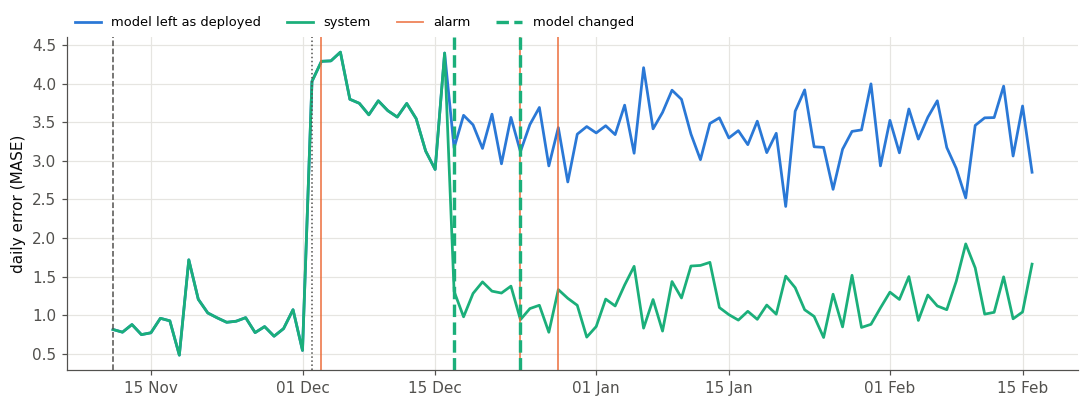

In [10]:
with_system, without = monitor.mase(t_change)   # error after the change: the system, the model left as deployed

no_follow_up = Monitor(s, "alarm_llm_gate", detector="residual_conformal", detector_value=multiplier, advisors={"llm": advisor})
no_follow_up.advance(len(y))                    # the same loop without follow-up reviews: it waits for the next alarm
waiting = no_follow_up.mase(t_change)[0]

result = pd.DataFrame({"error after the change (MASE)": [without, with_system, waiting]},
                      index=["model left as deployed", "system: detector, LLM advisor, check, follow-up reviews",
                             "the same without follow-up reviews"])
result["against the model left as deployed"] = [f"{100 * (e / without - 1):+.0f}%" for e in result.iloc[:, 0]]
display(result.round(2))

demo.plot_errors(s, {"model left as deployed": monitor.reference.pred, "system": monitor.run.pred}, monitor.scale,
                 alarms=monitor.alarms, applied=monitor.run.applied)

After the change the error is 1.70 with the system against 3.44 for the model left as deployed: 51% lower. From the day the model is changed the daily error falls back to about 1.2. The next alarm, on 23 December, leads to one more review: by then more new data is available, and the model is retrained again.

Without the follow-up reviews the model would wait for that second alarm, three weeks after the change (1.89). The follow-up reviews are an addition to the strategies evaluated in the thesis, which review the model on alarms only.

## 8. The Same Series in the Service (Grafana)

The service runs this loop behind an API and shows it in Grafana. Start it once from the root of the repository:

```bash
docker compose up --build -d
```

The next cell uploads the same CSV through `POST /series/csv` and starts a session on it. The dashboard then shows the values, the forecasts, the alarms and the reviews as the series plays (about 40 seconds).

In [11]:
session = demo.start_session(speed=60)   # 60 hours of data per second
if session:
    print("Session", session["id"], "is playing:", session["grafana_url"])

Session 16 is playing: http://localhost:3000/d/drift-monitor/drift-monitor?var-session=16&from=1384128000000&to=1389571200000&refresh=5s


The dashboard at the end of the series: the same three alarms, the four reviews and two model changes, and the same errors as above.

![Grafana dashboard of the demo series](../docs/images/grafana_demo_series.png)